In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/mk-gurucharan/Regression/master/Salary_Data.csv"

df = pd.read_csv(url)

print(df.head())
print(df.shape)
print(df.columns)

   YearsExperience   Salary
0              1.1  39343.0
1              1.3  46205.0
2              1.5  37731.0
3              2.0  43525.0
4              2.2  39891.0
(30, 2)
Index(['YearsExperience', 'Salary'], dtype='object')


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (30, 2)

Column Names:
Index(['YearsExperience', 'Salary'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes
None

Statistical Summary:
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000


In [ ]:
print(df.isnull().sum())

YearsExperience    0
Salary             0
dtype: int64


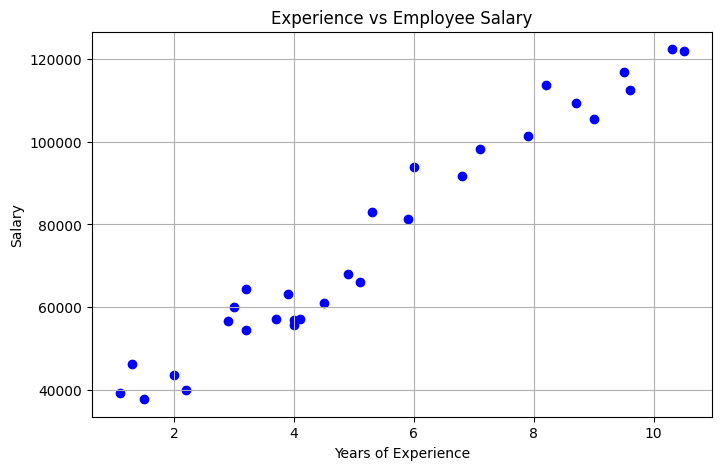

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['YearsExperience'],
    df['Salary'],
    color='blue'
)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Experience vs Employee Salary')

plt.grid()
plt.show()

In [ ]:
X = df[['YearsExperience']]

y = df['Salary']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 24
Testing Data: 6


In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

print("Slope:", model.coef_[0])

print("Intercept:", model.intercept_)

Model trained successfully!
Slope: 9423.815323030976
Intercept: 25321.583011776813


In [ ]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred
})

print(result)

   Actual Salary  Predicted Salary
0       112635.0     115790.210113
1        67938.0      71498.278095
2       113812.0     102596.868661
3        83088.0      75267.804224
4        64445.0      55477.792045
5        57189.0      60189.699707


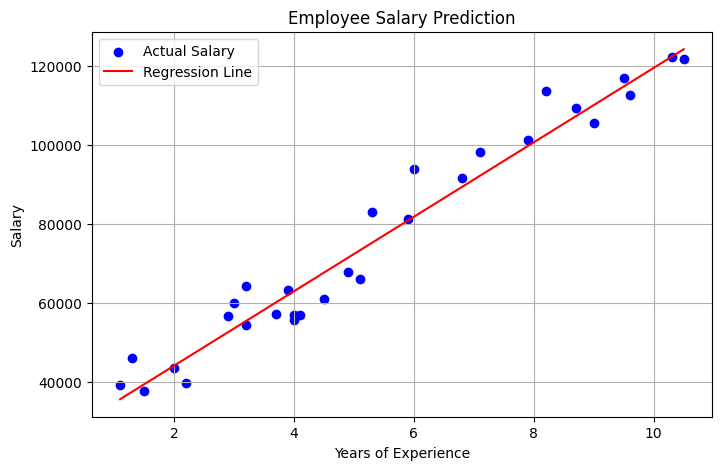

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    X,
    y,
    color='blue',
    label='Actual Salary'
)

plt.plot(
    X,
    model.predict(X),
    color='red',
    label='Regression Line'
)

plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.title('Employee Salary Prediction')

plt.legend()
plt.grid()

plt.show()

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2)

Mean Absolute Error: 6286.453830757749
Mean Squared Error: 49830096.85590839
Root Mean Squared Error: 7059.04362190151
R2 Score: 0.9024461774180497


In [ ]:
new_employees = pd.DataFrame({
    'YearsExperience': [2, 4, 6, 8, 10]
})

predictions = model.predict(new_employees)

new_employees['Predicted_Salary'] = predictions

print(new_employees)

   YearsExperience  Predicted_Salary
0                2      44169.213658
1                4      63016.844304
2                6      81864.474950
3                8     100712.105596
4               10     119559.736242
